# Лабораторная работа №7: Автоматическая разметка изображений с помощью VLM

**Версия:** студенческая  
**Курс:** «Современное компьютерное зрение»

> Сначала выполните notebook в режиме `FAST_DEV_RUN=True`, затем запускайте полный эксперимент. Сохраняйте метрики и checkpoints в `artifacts/`.

## Цели обучения

После работы студент должен уметь:

- Определить schema аннотации.
- Получить структурированные ответы VLM с retry.
- Проверить выборку человеком и обучить downstream baseline.


## Теоретическая часть

Авторазметка — это data pipeline: schema → generation → parsing → validation → confidence proxy → human audit. Нельзя терять сырой ответ модели: он нужен для трассировки ошибок и повторной обработки.


### Математическая постановка

Agreement для поля можно оценивать Cohen $\kappa=(p_o-p_e)/(1-p_e)$. Для редких классов важнее class-wise precision/recall, чем общая accuracy.


### Материалы

- [JSON Schema](https://json-schema.org/learn/getting-started-step-by-step)
- [Pydantic](https://docs.pydantic.dev/latest/)

Ссылки даны как дополнительный материал. При изменении API сверяйтесь с актуальной официальной документацией и фиксируйте версии зависимостей.


## Практический протокол

Полный эксперимент (`FAST_DEV_RUN=False`) требует GPU и ручной экспертизы captions. Классы CIFAR-10 служат проверяемым эталоном, а не ответами VLM. Установите torchvision, transformers, accelerate, bitsandbytes, pydantic, scikit-learn. В Colab сохраните `artifacts/` на Drive до начала инференса. FAST_DEV_RUN проверяет загрузку данных и схему без фиктивных метрик.

In [8]:
from pathlib import Path
import json, os, random, time
import numpy as np
SEED = 42
FAST_DEV_RUN = False  # True: проверка механики на малой выборке, НЕ отчётный эксперимент
ARTIFACTS = Path('artifacts'); ARTIFACTS.mkdir(exist_ok=True)
random.seed(SEED); np.random.seed(SEED)
def save_json(name, data):
    (ARTIFACTS/name).write_text(json.dumps(data, ensure_ascii=False, indent=2, default=str))

VLM_LOADER = "\n# Одна и та же квантованная модель и интерфейс используются для сравниваемых запусков.\n# В Colab предварительно: %pip install -q 'transformers>=4.51,<5' accelerate bitsandbytes pillow datasets\nimport torch\nfrom PIL import Image\nfrom transformers import AutoProcessor, Qwen2_5_VLForConditionalGeneration, BitsAndBytesConfig\nMODEL_ID = os.getenv('CV_VLM_MODEL', 'Qwen/Qwen2.5-VL-3B-Instruct')\nassert torch.cuda.is_available(), 'Требуется GPU для реального VLM-инференса; CPU smoke проверяет только данные и код.'\nquant = BitsAndBytesConfig(load_in_4bit=True, bnb_4bit_quant_type='nf4', bnb_4bit_compute_dtype=torch.float16)\nprocessor = AutoProcessor.from_pretrained(MODEL_ID)\nmodel = Qwen2_5_VLForConditionalGeneration.from_pretrained(MODEL_ID, quantization_config=quant, device_map='auto').eval()\ndef infer_image(path, prompt, adapter=None):\n    messages = [{'role':'user','content':[{'type':'image','image':Image.open(path).convert('RGB')},{'type':'text','text':prompt}]}]\n    text = processor.apply_chat_template(messages, tokenize=False, add_generation_prompt=True)\n    inputs = processor(text=[text], images=[Image.open(path).convert('RGB')], return_tensors='pt').to(model.device)\n    with torch.no_grad(): generated = model.generate(**inputs, max_new_tokens=96, do_sample=False)\n    return processor.batch_decode(generated[:, inputs.input_ids.shape[1]:], skip_special_tokens=True)[0].strip()\n"

In [9]:
%pip install -q "transformers>=4.51,<5" accelerate bitsandbytes pillow pydantic torchvision

## Оценивание

Десять обязательных предметных этапов — по 1 баллу каждый, всего 10 баллов. Отдельное творческое исследование — до 1 дополнительного балла. Каждый этап принимается по указанному наблюдаемому результату.

### Источник и классы

*Вес: 1 балл.*

**Постановка.** Этап «источник и классы» необходим для воспроизводимого предметного сравнения. Результат этого шага нельзя заменить синтетической оценкой или произвольной метрикой.

Выполните следующие действия:

1. Загрузите раздельные части CIFAR-10 и зафиксируйте перечень классов.
2. Сохраните и предъявите train/test CIFAR-10 и список классов.

**Результат.** train/test CIFAR-10 и список классов.

**Критерий принятия.** Задание считается принятым, если train/test CIFAR-10 и список классов получены из фактических входов этого этапа и доступны для проверки.

In [10]:
from pathlib import Path
import tarfile
from huggingface_hub import hf_hub_download
from torchvision.datasets import CIFAR10

DATA_DIR = Path('/content/data/cifar10')
DATA_DIR.mkdir(parents=True, exist_ok=True)

BATCHES = DATA_DIR / 'cifar-10-batches-py'
ARCHIVE = DATA_DIR / 'cifar-10-python.tar.gz'

if not BATCHES.is_dir():
    if not ARCHIVE.is_file():
        hf_hub_download(
            repo_id='uoft-cs/cifar10',
            filename='cifar-10-python.tar.gz',
            repo_type='dataset',
            local_dir=DATA_DIR,
        )
    with tarfile.open(ARCHIVE, 'r:gz') as tf:
        tf.extractall(DATA_DIR)

train_ds = CIFAR10(DATA_DIR, train=True,  download=False)
test_ds  = CIFAR10(DATA_DIR, train=False, download=False)
print(len(train_ds), len(test_ds))

/tmp/ipykernel_1433/2539749616.py:21: DeprecationWarning: Python 3.14 will, by default, filter extracted tar archives and reject files or modify their metadata. Use the filter argument to control this behavior.
  tf.extractall(DATA_DIR)


50000 10000


### Стратифицированный отбор изображений

*Вес: 1 балл.*

**Постановка.** Этап «стратифицированный отбор изображений» необходим для воспроизводимого предметного сравнения. Результат этого шага нельзя заменить синтетической оценкой или произвольной метрикой.

Выполните следующие действия:

1. Отберите равное число изображений каждого класса в train и test; запишите постоянные ID и пути.
2. Сохраните и предъявите пути и идентификаторы изображений по классам.

**Результат.** пути и идентификаторы изображений по классам.

**Критерий принятия.** Задание считается принятым, если пути и идентификаторы изображений по классам получены из фактических входов этого этапа и доступны для проверки.

In [14]:
import hashlib
from collections import Counter
from PIL import Image
N_TRAIN_PER_CLASS = 5 if FAST_DEV_RUN else 100       # одинаковое число изображений на класс
N_TEST_PER_CLASS = 5 if FAST_DEV_RUN else 50
rng = np.random.RandomState(SEED)

def sha(arr): return hashlib.sha1(arr.tobytes()).hexdigest()
train_hashes = {sha(a) for a in train_ds.data}
test_ok = np.array([sha(a) not in train_hashes for a in test_ds.data])    # исключаем точные дубли train в test
print('test-изображений, совпавших с train побайтно (исключены из отбора):', int((~test_ok).sum()))

def stratified_pick(ds, n_per_class, allowed=None):
    targets = np.array(ds.targets); out = {}
    for c, name in enumerate(CLASSES):
        cand = np.where(targets == c)[0]
        if allowed is not None: cand = cand[allowed[cand]]
        out[name] = sorted(int(i) for i in rng.choice(cand, n_per_class, replace=False))
    return out

sel_train = stratified_pick(train_ds, N_TRAIN_PER_CLASS)
sel_test = stratified_pick(test_ds, N_TEST_PER_CLASS, allowed=test_ok)

IMG_DIR = DATA_DIR / 'cifar10_subset'
def export(ds, split, selection):
    table = {}
    for name, idxs in selection.items():
        d = IMG_DIR / split / name; d.mkdir(parents=True, exist_ok=True); table[name] = []
        for i in idxs:
            p = d / f'{split}-{i:05d}.png'
            # 32x32 -> 224x224 (bicubic): VLM-процессору нужен достаточный размер; ID привязан к индексу CIFAR
            ds[i][0].convert('RGB').resize((224, 224), Image.BICUBIC).save(p)
            table[name].append({'id': f'{split}-{i:05d}', 'cifar_index': i, 'path': str(p)})
    return table

selection = {'train': export(train_ds, 'train', sel_train), 'test': export(test_ds, 'test', sel_test)}
for sp in selection:
    print(sp, {k: len(v) for k, v in selection[sp].items()})
save_json('selection.json', {'seed': SEED, 'n_train_per_class': N_TRAIN_PER_CLASS, 'n_test_per_class': N_TEST_PER_CLASS,
                             'selection': selection})

test-изображений, совпавших с train побайтно (исключены из отбора): 0
train {'airplane': 100, 'automobile': 100, 'bird': 100, 'cat': 100, 'deer': 100, 'dog': 100, 'frog': 100, 'horse': 100, 'ship': 100, 'truck': 100}
test {'airplane': 50, 'automobile': 50, 'bird': 50, 'cat': 50, 'deer': 50, 'dog': 50, 'frog': 50, 'horse': 50, 'ship': 50, 'truck': 50}


In [ ]:
CLASSES = list(train_ds.classes)
assert CLASSES == list(test_ds.classes) and len(CLASSES) == 10

### Манифест изображений

*Вес: 1 балл.*

**Постановка.** Этап «манифест изображений» необходим для воспроизводимого предметного сравнения. Результат этого шага нельзя заменить синтетической оценкой или произвольной метрикой.

Выполните следующие действия:

1. Проверьте объём выборок и сохраните манифест с эталонными метками, не передавая их VLM.
2. Сохраните и предъявите artifacts/images.jsonl без пересечения train/test.

**Результат.** artifacts/images.jsonl без пересечения train/test.

**Критерий принятия.** Задание считается принятым, если artifacts/images.jsonl без пересечения train/test получены из фактических входов этого этапа и доступны для проверки.

In [15]:
records = []
for split, ds in (('train', train_ds), ('test', test_ds)):
    for c, name in enumerate(CLASSES):
        for e in selection[split][name]:
            records.append({'id': e['id'], 'split': split, 'path': e['path'], 'cifar_index': e['cifar_index'],
                            'gold_label': c, 'gold_class': name, 'sha1': sha(ds.data[e['cifar_index']])})

# проверки объёма и непересечения
for split, n in (('train', N_TRAIN_PER_CLASS), ('test', N_TEST_PER_CLASS)):
    cnt = Counter(r['gold_class'] for r in records if r['split'] == split)
    assert set(cnt) == set(CLASSES) and set(cnt.values()) == {n}, cnt
ids_tr = {r['id'] for r in records if r['split'] == 'train'}; ids_te = {r['id'] for r in records if r['split'] == 'test'}
h_tr = {r['sha1'] for r in records if r['split'] == 'train'}; h_te = {r['sha1'] for r in records if r['split'] == 'test'}
assert len(ids_tr) + len(ids_te) == len(records)                    # ID уникальны
assert not ids_tr & ids_te and not h_tr & h_te                      # без пересечения по ID и по содержимому
assert all(Path(r['path']).is_file() for r in records)

# Манифест содержит эталонные метки для оценки, но VLM получает только path и PROMPT (метки VLM не передаются).
with (ARTIFACTS / 'images.jsonl').open('w') as f:
    for r in records: f.write(json.dumps(r, ensure_ascii=False) + '\n')
print('images.jsonl:', len(records), 'записей; train', len(ids_tr), 'test', len(ids_te))

images.jsonl: 1500 записей; train 1000 test 500


### Схема и парсер VLM-ответа

*Вес: 1 балл.*

**Постановка.** Этап «схема и парсер vlm-ответа» необходим для воспроизводимого предметного сравнения. Результат этого шага нельзя заменить синтетической оценкой или произвольной метрикой.

Выполните следующие действия:

1. Определите строгую схему class_name, caption, uncertain; отклоняйте незнакомые классы и пустые описания.
2. Сохраните и предъявите типизированная схема, prompt и функция parse.

**Результат.** типизированная схема, prompt и функция parse.

**Критерий принятия.** Задание считается принятым, если типизированная схема, prompt и функция parse получены из фактических входов этого этапа и доступны для проверки.

In [16]:
import re
from typing import Literal
from pydantic import BaseModel, ConfigDict, ValidationError, field_validator

ClassName = Literal[tuple(CLASSES)]                  # допустимы только классы CIFAR-10

class Annotation(BaseModel):
    model_config = ConfigDict(extra='forbid', strict=True)      # никаких лишних полей, никаких неявных приведений типов
    class_name: ClassName
    caption: str
    uncertain: bool
    @field_validator('class_name', mode='before')
    @classmethod
    def _norm_class(cls, v):
        return v.strip().lower() if isinstance(v, str) else v   # допускаем только регистр/пробелы; незнакомый класс отклоняется
    @field_validator('caption')
    @classmethod
    def _caption_nonempty(cls, v):
        v = v.strip()
        if len(v) < 3: raise ValueError('caption пустой или слишком короткий')
        return v

PROMPT = (
    'You are annotating a small photo for an image classification dataset.\n'
    f'Choose exactly one class from this list: {", ".join(CLASSES)}.\n'
    'Reply with ONE JSON object and nothing else, with exactly these keys:\n'
    '"class_name": one class from the list; '
    '"caption": one short English sentence describing what is visible; '
    '"uncertain": true if you are not sure about the class, otherwise false.\n'
    'Example: {"class_name": "cat", "caption": "A grey cat lying on a sofa.", "uncertain": false}'
)

class ParseError(ValueError): pass

def extract_json(text):
    t = text.strip()
    t = re.sub(r'^```(?:json)?\s*|\s*```$', '', t, flags=re.S).strip()      # снимаем markdown-ограждение
    a, b = t.find('{'), t.rfind('}')
    if a < 0 or b <= a: raise ParseError('в ответе нет JSON-объекта')
    try: obj = json.loads(t[a:b + 1])
    except json.JSONDecodeError as e: raise ParseError(f'некорректный JSON: {e.msg}')
    if not isinstance(obj, dict): raise ParseError('JSON не является объектом')
    return obj

def parse(text):
    """Строгий разбор ответа VLM -> Annotation либо ParseError (с понятной причиной)."""
    obj = extract_json(text)
    try: return Annotation.model_validate(obj)
    except ValidationError as e:
        raise ParseError('; '.join(f"{'.'.join(map(str, x['loc']))}: {x['msg']}" for x in e.errors()))

def build_retry_prompt(prompt, error):
    # Декодирование жадное (do_sample=False): тот же prompt дал бы тот же ответ, поэтому при повторе добавляем причину ошибки.
    return (prompt + f'\n\nYour previous reply was rejected: {error}. '
            'Reply again with ONLY one valid JSON object with keys class_name, caption, uncertain.')

PROMPT_SHA1 = hashlib.sha1(PROMPT.encode()).hexdigest()
print(PROMPT); print('\nсхема:', json.dumps(Annotation.model_json_schema(), ensure_ascii=False)[:300], '...')
(ARTIFACTS / 'prompt.txt').write_text(PROMPT)
save_json('annotation_schema.json', Annotation.model_json_schema())

You are annotating a small photo for an image classification dataset.
Choose exactly one class from this list: airplane, automobile, bird, cat, deer, dog, frog, horse, ship, truck.
Reply with ONE JSON object and nothing else, with exactly these keys:
"class_name": one class from the list; "caption": one short English sentence describing what is visible; "uncertain": true if you are not sure about the class, otherwise false.
Example: {"class_name": "cat", "caption": "A grey cat lying on a sofa.", "uncertain": false}

схема: {"additionalProperties": false, "properties": {"class_name": {"enum": ["airplane", "automobile", "bird", "cat", "deer", "dog", "frog", "horse", "ship", "truck"], "title": "Class Name", "type": "string"}, "caption": {"title": "Caption", "type": "string"}, "uncertain": {"title": "Uncertain", "type": " ...


### Возобновляемое получение аннотаций

*Вес: 1 балл.*

**Постановка.** Этап «возобновляемое получение аннотаций» необходим для воспроизводимого предметного сравнения. Результат этого шага нельзя заменить синтетической оценкой или произвольной метрикой.

Выполните следующие действия:

1. Вызовите Qwen2.5-VL для каждого изображения, повторяйте ошибочный JSON до трёх раз и сохраняйте исходные ответы по ID.
2. Сохраните и предъявите artifacts/annotations.jsonl с сырыми ответами и временем.

**Результат.** artifacts/annotations.jsonl с сырыми ответами и временем.

**Критерий принятия.** Задание считается принятым, если artifacts/annotations.jsonl с сырыми ответами и временем получены из фактических входов этого этапа и доступны для проверки.

In [17]:
MAX_RETRIES = 3                                     # до трёх повторов после первой попытки (до 4 вызовов на изображение)
HAVE_VLM = not FAST_DEV_RUN                         # FAST_DEV_RUN: VLM не запускается, метрики не вычисляются
ANN_PATH = ARTIFACTS / 'annotations.jsonl'
MODEL_NAME = os.getenv('CV_VLM_MODEL', 'Qwen/Qwen2.5-VL-3B-Instruct')

def load_jsonl(path):
    path = Path(path)
    return [json.loads(s) for s in path.read_text().splitlines() if s.strip()] if path.exists() else []

def annotate_all(recs, infer_fn, out_path, prompt=PROMPT, max_retries=MAX_RETRIES, log_every=50):
    """Возобновляемая разметка: уже обработанные ID пропускаются, каждая запись сразу дописывается и сбрасывается на диск.
    Сохраняются ВСЕ сырые ответы всех попыток, время и причина отклонения."""
    out_path = Path(out_path)
    done = {r['id'] for r in load_jsonl(out_path)}
    todo = [r for r in recs if r['id'] not in done]
    print(f'всего {len(recs)}, уже готово {len(done)}, к обработке {len(todo)}')
    with out_path.open('a') as f:
        for n, rec in enumerate(todo, 1):
            t0, attempts, ann, cur = time.time(), [], None, prompt
            for a in range(1, max_retries + 2):
                t1, raw, err = time.time(), '', None
                try: raw = infer_fn(rec['path'], cur)                   # VLM видит только изображение и prompt
                except Exception as e: err = f'ошибка инференса: {e!r}'
                if err is None:
                    try: ann = parse(raw)
                    except ParseError as e: err = str(e)
                attempts.append({'attempt': a, 'raw': raw, 'error': err, 'seconds': round(time.time() - t1, 3)})
                if err is None: break
                cur = build_retry_prompt(prompt, err)
            f.write(json.dumps({
                'id': rec['id'], 'split': rec['split'], 'path': rec['path'], 'attempts': attempts,
                'raw_response': attempts[-1]['raw'], 'parsed': ann.model_dump() if ann else None, 'valid': ann is not None,
                'n_attempts': len(attempts), 'seconds_total': round(time.time() - t0, 3),
                'model': MODEL_NAME, 'prompt_sha1': PROMPT_SHA1,
                'timestamp': time.strftime('%Y-%m-%dT%H:%M:%S')}, ensure_ascii=False) + '\n')
            f.flush()
            if n % log_every == 0: print(f'  {n}/{len(todo)}')

if HAVE_VLM:
    exec(VLM_LOADER, globals())                     # загружает processor, model, infer_image (Qwen2.5-VL, 4-bit NF4)
    annotate_all(records, infer_image, ANN_PATH)
    rows = load_jsonl(ANN_PATH)
    print('записей:', len(rows), '| валидных:', sum(r['valid'] for r in rows),
          '| ср. число попыток: %.2f' % np.mean([r['n_attempts'] for r in rows]),
          '| ср. время на изображение: %.2fs' % np.mean([r['seconds_total'] for r in rows]))
else:
    print('FAST_DEV_RUN=True: инференс VLM пропущен (нужен GPU). annotations.jsonl не создаётся.')

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


preprocessor_config.json:   0%|          | 0.00/350 [00:00<?, ?B/s]

The image processor of type `Qwen2VLImageProcessor` is now loaded as a fast processor by default, even if the model checkpoint was saved with a slow processor. This is a breaking change and may produce slightly different outputs. To continue using the slow processor, instantiate this class with `use_fast=False`. Note that this behavior will be extended to all models in a future release.


tokenizer_config.json: 0.00B [00:00, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

...

generation_config.json:   0%|          | 0.00/216 [00:00<?, ?B/s]

The following generation flags are not valid and may be ignored: ['temperature']. Set `TRANSFORMERS_VERBOSITY=info` for more details.


всего 1500, уже готово 0, к обработке 1500


/usr/local/lib/python3.13/dist-packages/bitsandbytes/backends/cuda/ops.py:957: UserWarning: inner dimension (3420) is not aligned for fast kernel with blocksize=64, falling back to slower implementation.
  warn(


  50/1500
  100/1500
  150/1500
  200/1500
  250/1500
  300/1500
  350/1500
  400/1500
  450/1500
  500/1500
  550/1500
  600/1500
  650/1500
  700/1500
  750/1500
  800/1500
  850/1500
  900/1500
  950/1500
  1000/1500
  1050/1500
  1100/1500
  1150/1500
  1200/1500
  1250/1500
  1300/1500
  1350/1500
  1400/1500
  1450/1500
  1500/1500
записей: 1500 | валидных: 1492 | ср. число попыток: 1.02 | ср. время на изображение: 3.17s


### Проверка формата без GPU

*Вес: 1 балл.*

**Постановка.** Этап «проверка формата без gpu» необходим для воспроизводимого предметного сравнения. Результат этого шага нельзя заменить синтетической оценкой или произвольной метрикой.

Выполните следующие действия:

1. В smoke-режиме проверьте только разбор валидного ответа, не вычисляя качество VLM.
2. Сохраните и предъявите проверка JSON-схемы в smoke-режиме.

**Результат.** проверка JSON-схемы в smoke-режиме.

**Критерий принятия.** Задание считается принятым, если проверка JSON-схемы в smoke-режиме получены из фактических входов этого этапа и доступны для проверки.

In [18]:
# Проверка только формата/схемы (без GPU и без оценки качества VLM): синтетические строки проверяют лишь parse().
smoke_cases = [
    ('valid',           '{"class_name": "cat", "caption": "A grey cat on a sofa.", "uncertain": false}', True),
    ('valid_fenced',    '```json\n{"class_name": "Ship", "caption": "A large ship at sea.", "uncertain": true}\n```', True),
    ('unknown_class',   '{"class_name": "dragon", "caption": "A dragon.", "uncertain": false}', False),
    ('empty_caption',   '{"class_name": "dog", "caption": "   ", "uncertain": false}', False),
    ('not_json',        'It is a cat.', False),
    ('extra_field',     '{"class_name": "cat", "caption": "A cat.", "uncertain": false, "score": 0.9}', False),
    ('missing_field',   '{"class_name": "cat", "caption": "A cat."}', False),
    ('uncertain_str',   '{"class_name": "cat", "caption": "A cat.", "uncertain": "false"}', False),
]
smoke_out = []
for name, text, expect in smoke_cases:
    try: parse(text); ok, err = True, None
    except ParseError as e: ok, err = False, str(e)
    smoke_out.append({'case': name, 'expected_valid': expect, 'got_valid': ok, 'error': err})
    print(f"{name:15s} ожидалось={expect!s:5s} получено={ok!s:5s} {err or ''}")
assert all(r['expected_valid'] == r['got_valid'] for r in smoke_out), 'схема/parse ведут себя не так, как задумано'
assert parse(smoke_cases[0][1]).class_name == 'cat'
retry = build_retry_prompt(PROMPT, 'x'); assert retry != PROMPT                 # повтор меняет prompt
save_json('schema_check.json', {'mode': 'FAST_DEV_RUN' if FAST_DEV_RUN else 'full', 'cases': smoke_out,
                                'note': 'проверяется только разбор формата; качество VLM здесь не измеряется'})

valid           ожидалось=True  получено=True  
valid_fenced    ожидалось=True  получено=True  
unknown_class   ожидалось=False получено=False class_name: Input should be 'airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship' or 'truck'
empty_caption   ожидалось=False получено=False caption: Value error, caption пустой или слишком короткий
not_json        ожидалось=False получено=False в ответе нет JSON-объекта
extra_field     ожидалось=False получено=False score: Extra inputs are not permitted
missing_field   ожидалось=False получено=False uncertain: Field required
uncertain_str   ожидалось=False получено=False uncertain: Input should be a valid boolean


### Покрытие и матрица ошибок

*Вес: 1 балл.*

**Постановка.** Этап «покрытие и матрица ошибок» необходим для воспроизводимого предметного сравнения. Результат этого шага нельзя заменить синтетической оценкой или произвольной метрикой.

Выполните следующие действия:

1. Подсчитайте coverage, precision/recall и матрицу ошибок только по настоящим ответам модели на test.
2. Сохраните и предъявите artifacts/quality.json по ответам VLM.

**Результат.** artifacts/quality.json по ответам VLM.

**Критерий принятия.** Задание считается принятым, если artifacts/quality.json по ответам VLM получены из фактических входов этого этапа и доступны для проверки.

test: coverage=0.996  acc(valid)=0.821  acc(strict)=0.818  macro-F1=0.829  kappa=0.801
  airplane    P=0.87 R=0.90 n=50
  automobile  P=1.00 R=0.90 n=50
  bird        P=0.93 R=0.84 n=50
  cat         P=0.96 R=0.54 n=50
  deer        P=1.00 R=0.80 n=50
  dog         P=0.47 R=0.98 n=50
  frog        P=1.00 R=0.70 n=50
  horse       P=0.94 R=0.92 n=50
  ship        P=1.00 R=0.62 n=48
  truck       P=0.71 R=1.00 n=50


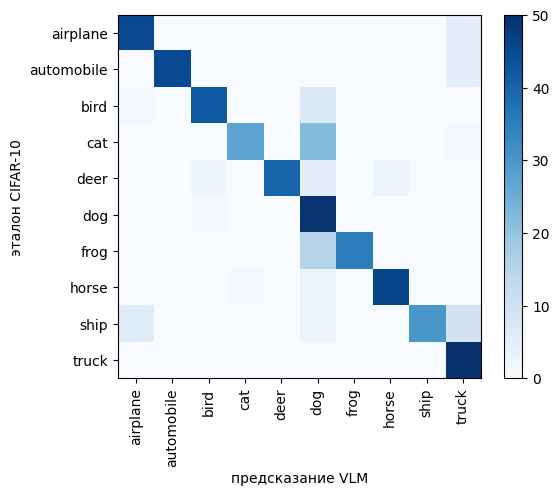

In [19]:
from sklearn.metrics import precision_recall_fscore_support, confusion_matrix, cohen_kappa_score
gold_cls = {r['id']: r['gold_class'] for r in records}

def quality_report(split):
    ann = {r['id']: r for r in load_jsonl(ANN_PATH)}
    ids = [r['id'] for r in records if r['split'] == split]
    missing = [i for i in ids if i not in ann]
    assert not missing, f'нет аннотаций для {len(missing)} изображений split={split}'
    valid = [i for i in ids if ann[i]['valid']]
    y_true = [gold_cls[i] for i in valid]; y_pred = [ann[i]['parsed']['class_name'] for i in valid]
    p, r, f, s = precision_recall_fscore_support(y_true, y_pred, labels=CLASSES, zero_division=0)
    unc = np.array([ann[i]['parsed']['uncertain'] for i in valid]); ok = np.array(y_true) == np.array(y_pred)
    return {'split': split, 'n_images': len(ids), 'n_valid': len(valid), 'coverage': len(valid) / len(ids),
            'accuracy_on_valid': float(ok.mean()) if len(valid) else None,
            'accuracy_strict_invalid_as_wrong': float(ok.sum() / len(ids)),
            'macro_f1': float(f.mean()), 'cohen_kappa': float(cohen_kappa_score(y_true, y_pred)) if len(valid) else None,
            'per_class': {c: {'precision': float(p[k]), 'recall': float(r[k]), 'f1': float(f[k]), 'support': int(s[k])} for k, c in enumerate(CLASSES)},
            'labels_order': CLASSES, 'confusion_matrix_true_x_pred': confusion_matrix(y_true, y_pred, labels=CLASSES).tolist(),
            'uncertain_rate': float(unc.mean()) if len(valid) else None,
            'accuracy_when_uncertain': float(ok[unc].mean()) if unc.any() else None,
            'accuracy_when_certain': float(ok[~unc].mean()) if (~unc).any() else None,
            'mean_attempts': float(np.mean([ann[i]['n_attempts'] for i in ids])),
            'mean_seconds_per_image': float(np.mean([ann[i]['seconds_total'] for i in ids]))}

if HAVE_VLM:
    quality = quality_report('test')                       # только настоящие ответы модели на test
    save_json('quality.json', quality)
    print(f"test: coverage={quality['coverage']:.3f}  acc(valid)={quality['accuracy_on_valid']:.3f}  "
          f"acc(strict)={quality['accuracy_strict_invalid_as_wrong']:.3f}  macro-F1={quality['macro_f1']:.3f}  kappa={quality['cohen_kappa']:.3f}")
    for c, v in quality['per_class'].items(): print(f"  {c:11s} P={v['precision']:.2f} R={v['recall']:.2f} n={v['support']}")
    plt_cm = np.array(quality['confusion_matrix_true_x_pred'])
    import matplotlib.pyplot as plt
    fig, ax = plt.subplots(figsize=(6, 5)); im = ax.imshow(plt_cm, cmap='Blues')
    ax.set_xticks(range(10)); ax.set_xticklabels(CLASSES, rotation=90); ax.set_yticks(range(10)); ax.set_yticklabels(CLASSES)
    ax.set_xlabel('предсказание VLM'); ax.set_ylabel('эталон CIFAR-10'); plt.colorbar(im); plt.tight_layout()
    plt.savefig(ARTIFACTS / 'confusion_matrix.png', dpi=130); plt.show()
else:
    print('FAST_DEV_RUN: метрики VLM не вычисляются (нет реальных ответов модели).')

### Экспертная оценка описаний

*Вес: 1 балл.*

**Постановка.** Этап «экспертная оценка описаний» необходим для воспроизводимого предметного сравнения. Результат этого шага нельзя заменить синтетической оценкой или произвольной метрикой.

Выполните следующие действия:

1. Соберите отдельные экспертные оценки подписей и не подменяйте их пустым файлом.
2. Сохраните и предъявите artifacts/human_audit.jsonl с экспертными записями.

**Результат.** artifacts/human_audit.jsonl с экспертными записями.

**Критерий принятия.** Задание считается принятым, если artifacts/human_audit.jsonl с экспертными записями получены из фактических входов этого этапа и доступны для проверки.

Имя/идентификатор эксперта: expert


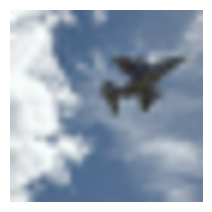

[train-06504] Ваш класс (0=airplane, 1=automobile, 2=bird, 3=cat, 4=deer, 5=dog, 6=frog, 7=horse, 8=ship, 9=truck); q - выход: 0
   VLM: класс=airplane; подпись: An airplane flying in the sky.
   Оценка подписи: 0=неверна, 1=частично, 2=верна: 2


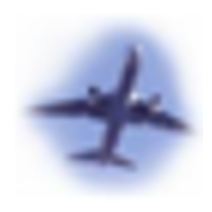

[train-00650] Ваш класс (0=airplane, 1=automobile, 2=bird, 3=cat, 4=deer, 5=dog, 6=frog, 7=horse, 8=ship, 9=truck); q - выход: 0
   VLM: класс=airplane; подпись: A blue airplane flying in the sky.
   Оценка подписи: 0=неверна, 1=частично, 2=верна: 1


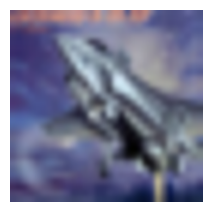

[train-04816] Ваш класс (0=airplane, 1=automobile, 2=bird, 3=cat, 4=deer, 5=dog, 6=frog, 7=horse, 8=ship, 9=truck); q - выход: 0
   VLM: класс=airplane; подпись: A sleek airplane flying through the sky.
   Оценка подписи: 0=неверна, 1=частично, 2=верна: 2


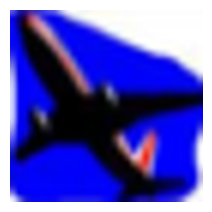

[train-07243] Ваш класс (0=airplane, 1=automobile, 2=bird, 3=cat, 4=deer, 5=dog, 6=frog, 7=horse, 8=ship, 9=truck); q - выход: 0
   VLM: класс=airplane; подпись: A blue airplane flying in the sky.
   Оценка подписи: 0=неверна, 1=частично, 2=верна: 0


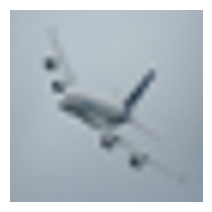

[train-26311] Ваш класс (0=airplane, 1=automobile, 2=bird, 3=cat, 4=deer, 5=dog, 6=frog, 7=horse, 8=ship, 9=truck); q - выход: 0
   VLM: класс=airplane; подпись: An airplane flying in the sky.
   Оценка подписи: 0=неверна, 1=частично, 2=верна: 2


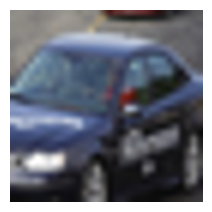

[train-20725] Ваш класс (0=airplane, 1=automobile, 2=bird, 3=cat, 4=deer, 5=dog, 6=frog, 7=horse, 8=ship, 9=truck); q - выход: 1
   VLM: класс=automobile; подпись: A blue car driving on a road.
   Оценка подписи: 0=неверна, 1=частично, 2=верна: 2


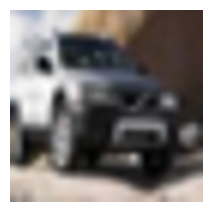

[train-16937] Ваш класс (0=airplane, 1=automobile, 2=bird, 3=cat, 4=deer, 5=dog, 6=frog, 7=horse, 8=ship, 9=truck); q - выход: 1
   VLM: класс=automobile; подпись: A black SUV parked in front of a building.
   Оценка подписи: 0=неверна, 1=частично, 2=верна: 0


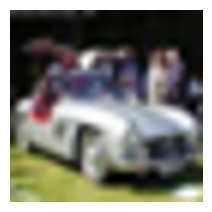

[train-41602] Ваш класс (0=airplane, 1=automobile, 2=bird, 3=cat, 4=deer, 5=dog, 6=frog, 7=horse, 8=ship, 9=truck); q - выход: 1
   VLM: класс=automobile; подпись: A vintage car with a white body and red accents.
   Оценка подписи: 0=неверна, 1=частично, 2=верна: 1


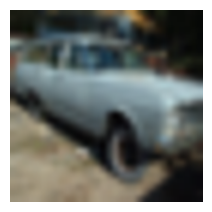

[train-42715] Ваш класс (0=airplane, 1=automobile, 2=bird, 3=cat, 4=deer, 5=dog, 6=frog, 7=horse, 8=ship, 9=truck); q - выход: 1
   VLM: класс=automobile; подпись: An old-fashioned car parked in front of a building.
   Оценка подписи: 0=неверна, 1=частично, 2=верна: 2


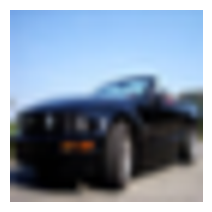

[train-43797] Ваш класс (0=airplane, 1=automobile, 2=bird, 3=cat, 4=deer, 5=dog, 6=frog, 7=horse, 8=ship, 9=truck); q - выход: 1
   VLM: класс=automobile; подпись: A black car parked outdoors.
   Оценка подписи: 0=неверна, 1=частично, 2=верна: 2


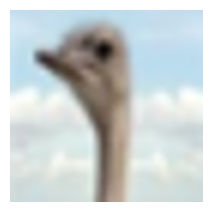

[train-07974] Ваш класс (0=airplane, 1=automobile, 2=bird, 3=cat, 4=deer, 5=dog, 6=frog, 7=horse, 8=ship, 9=truck); q - выход: 2
   VLM: класс=bird; подпись: A bird flying in the sky with its wings spread wide.
   Оценка подписи: 0=неверна, 1=частично, 2=верна: 0


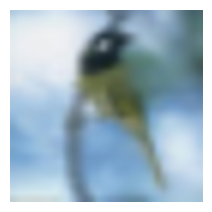

[train-22448] Ваш класс (0=airplane, 1=automobile, 2=bird, 3=cat, 4=deer, 5=dog, 6=frog, 7=horse, 8=ship, 9=truck); q - выход: 2
   VLM: класс=bird; подпись: A small bird flying in the sky.
   Оценка подписи: 0=неверна, 1=частично, 2=верна: 0


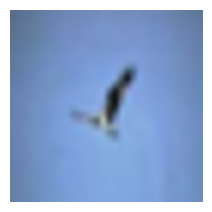

[train-37464] Ваш класс (0=airplane, 1=automobile, 2=bird, 3=cat, 4=deer, 5=dog, 6=frog, 7=horse, 8=ship, 9=truck); q - выход: 2
   VLM: класс=bird; подпись: A bird flying in the sky.
   Оценка подписи: 0=неверна, 1=частично, 2=верна: 2


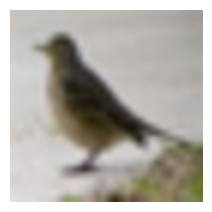

[train-01918] Ваш класс (0=airplane, 1=automobile, 2=bird, 3=cat, 4=deer, 5=dog, 6=frog, 7=horse, 8=ship, 9=truck); q - выход: 2
   VLM: класс=bird; подпись: A small bird standing on a branch.
   Оценка подписи: 0=неверна, 1=частично, 2=верна: 2


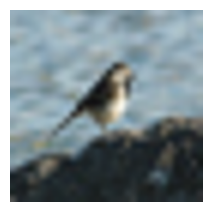

[train-14106] Ваш класс (0=airplane, 1=automobile, 2=bird, 3=cat, 4=deer, 5=dog, 6=frog, 7=horse, 8=ship, 9=truck); q - выход: 2
   VLM: класс=bird; подпись: A small bird perched on a rock.
   Оценка подписи: 0=неверна, 1=частично, 2=верна: 2


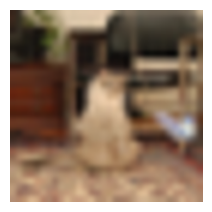

[train-47100] Ваш класс (0=airplane, 1=automobile, 2=bird, 3=cat, 4=deer, 5=dog, 6=frog, 7=horse, 8=ship, 9=truck); q - выход: 3
   VLM: класс=cat; подпись: A fluffy cat sitting on a rug in front of a TV.
   Оценка подписи: 0=неверна, 1=частично, 2=верна: 2


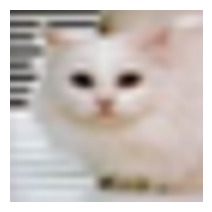

[train-18993] Ваш класс (0=airplane, 1=automobile, 2=bird, 3=cat, 4=deer, 5=dog, 6=frog, 7=horse, 8=ship, 9=truck); q - выход: 3
   VLM: класс=cat; подпись: A white cat sitting on a keyboard.
   Оценка подписи: 0=неверна, 1=частично, 2=верна: 0


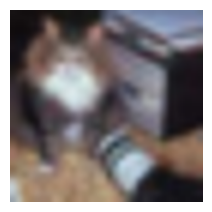

[train-27662] Ваш класс (0=airplane, 1=automobile, 2=bird, 3=cat, 4=deer, 5=dog, 6=frog, 7=horse, 8=ship, 9=truck); q - выход: 3
   VLM: класс=dog; подпись: A person holding a dog in their arms.
   Оценка подписи: 0=неверна, 1=частично, 2=верна: 0


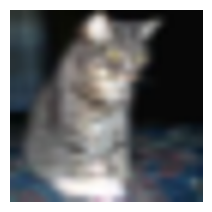

[train-34437] Ваш класс (0=airplane, 1=automobile, 2=bird, 3=cat, 4=deer, 5=dog, 6=frog, 7=horse, 8=ship, 9=truck); q - выход: 3
   VLM: класс=cat; подпись: A gray cat sitting on a patterned surface.
   Оценка подписи: 0=неверна, 1=частично, 2=верна: 2


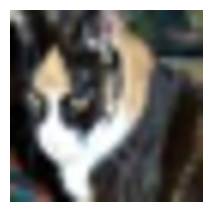

[train-48914] Ваш класс (0=airplane, 1=automobile, 2=bird, 3=cat, 4=deer, 5=dog, 6=frog, 7=horse, 8=ship, 9=truck); q - выход: 3
   VLM: класс=dog; подпись: A black and white dog wearing a blue collar.
   Оценка подписи: 0=неверна, 1=частично, 2=верна: 0


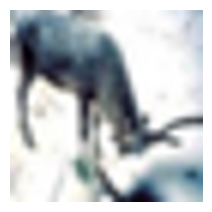

[train-38941] Ваш класс (0=airplane, 1=automobile, 2=bird, 3=cat, 4=deer, 5=dog, 6=frog, 7=horse, 8=ship, 9=truck); q - выход: 4
   VLM: класс=deer; подпись: A deer standing in a forest clearing.
   Оценка подписи: 0=неверна, 1=частично, 2=верна: 2


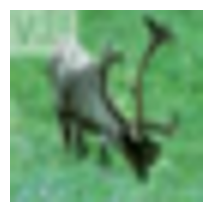

[train-46253] Ваш класс (0=airplane, 1=automobile, 2=bird, 3=cat, 4=deer, 5=dog, 6=frog, 7=horse, 8=ship, 9=truck); q - выход: 4
   VLM: класс=deer; подпись: A deer standing in a grassy field.
   Оценка подписи: 0=неверна, 1=частично, 2=верна: 2


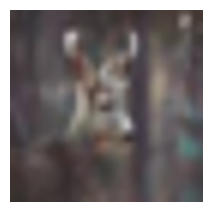

[train-08137] Ваш класс (0=airplane, 1=automobile, 2=bird, 3=cat, 4=deer, 5=dog, 6=frog, 7=horse, 8=ship, 9=truck); q - выход: 4
   VLM: класс=dog; подпись: A small dog wearing a red collar.
   Оценка подписи: 0=неверна, 1=частично, 2=верна: 0


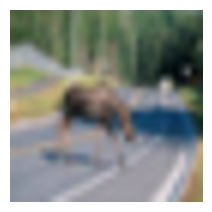

[train-28072] Ваш класс (0=airplane, 1=automobile, 2=bird, 3=cat, 4=deer, 5=dog, 6=frog, 7=horse, 8=ship, 9=truck); q - выход: 4
   VLM: класс=deer; подпись: A moose crossing a road in a forested area.
   Оценка подписи: 0=неверна, 1=частично, 2=верна: 0


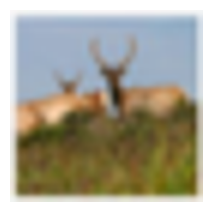

[train-05179] Ваш класс (0=airplane, 1=automobile, 2=bird, 3=cat, 4=deer, 5=dog, 6=frog, 7=horse, 8=ship, 9=truck); q - выход: 4
   VLM: класс=deer; подпись: A deer with antlers standing in a grassy field.
   Оценка подписи: 0=неверна, 1=частично, 2=верна: 2


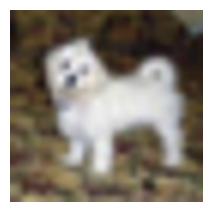

[train-24153] Ваш класс (0=airplane, 1=automobile, 2=bird, 3=cat, 4=deer, 5=dog, 6=frog, 7=horse, 8=ship, 9=truck); q - выход: 5
   VLM: класс=dog; подпись: A small white dog standing on a carpeted floor.
   Оценка подписи: 0=неверна, 1=частично, 2=верна: 2


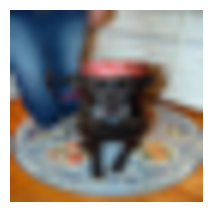

[train-27977] Ваш класс (0=airplane, 1=automobile, 2=bird, 3=cat, 4=deer, 5=dog, 6=frog, 7=horse, 8=ship, 9=truck); q - выход: 5
   VLM: класс=dog; подпись: A dog sitting on a colorful rug.
   Оценка подписи: 0=неверна, 1=частично, 2=верна: 2


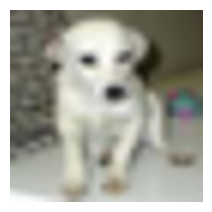

[train-30372] Ваш класс (0=airplane, 1=automobile, 2=bird, 3=cat, 4=deer, 5=dog, 6=frog, 7=horse, 8=ship, 9=truck); q - выход: 5
   VLM: класс=dog; подпись: A small white puppy standing on a carpeted floor.
   Оценка подписи: 0=неверна, 1=частично, 2=верна: 2


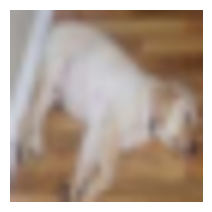

[train-09355] Ваш класс (0=airplane, 1=automobile, 2=bird, 3=cat, 4=deer, 5=dog, 6=frog, 7=horse, 8=ship, 9=truck); q - выход: 5
   VLM: класс=dog; подпись: A small white dog standing on a wooden floor.
   Оценка подписи: 0=неверна, 1=частично, 2=верна: 1


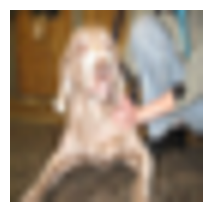

[train-09746] Ваш класс (0=airplane, 1=automobile, 2=bird, 3=cat, 4=deer, 5=dog, 6=frog, 7=horse, 8=ship, 9=truck); q - выход: 5
   VLM: класс=dog; подпись: A golden retriever being petted by its owner.
   Оценка подписи: 0=неверна, 1=частично, 2=верна: 2


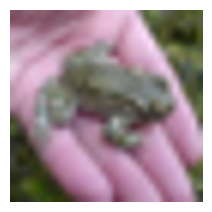

[train-15360] Ваш класс (0=airplane, 1=automobile, 2=bird, 3=cat, 4=deer, 5=dog, 6=frog, 7=horse, 8=ship, 9=truck); q - выход: 6
   VLM: класс=frog; подпись: A small frog being held in someone's hand.
   Оценка подписи: 0=неверна, 1=частично, 2=верна: 2


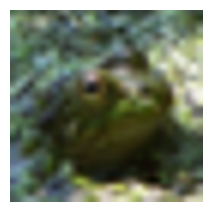

[train-11726] Ваш класс (0=airplane, 1=automobile, 2=bird, 3=cat, 4=deer, 5=dog, 6=frog, 7=horse, 8=ship, 9=truck); q - выход: 6
   VLM: класс=frog; подпись: A frog sitting on a leaf in a forest.
   Оценка подписи: 0=неверна, 1=частично, 2=верна: 2


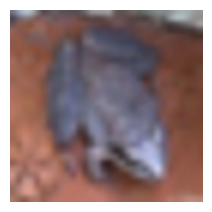

[train-44128] Ваш класс (0=airplane, 1=automobile, 2=bird, 3=cat, 4=deer, 5=dog, 6=frog, 7=horse, 8=ship, 9=truck); q - выход: 6
   VLM: класс=frog; подпись: A gray frog sitting on a wooden surface.
   Оценка подписи: 0=неверна, 1=частично, 2=верна: 2


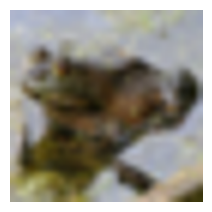

[train-05898] Ваш класс (0=airplane, 1=automobile, 2=bird, 3=cat, 4=deer, 5=dog, 6=frog, 7=horse, 8=ship, 9=truck); q - выход: 6
   VLM: класс=frog; подпись: A frog sitting on a tree branch in a forest.
   Оценка подписи: 0=неверна, 1=частично, 2=верна: 1


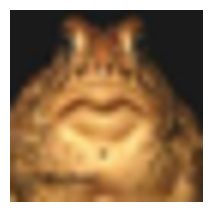

[train-22889] Ваш класс (0=airplane, 1=automobile, 2=bird, 3=cat, 4=deer, 5=dog, 6=frog, 7=horse, 8=ship, 9=truck); q - выход: 6
   VLM: класс=cat; подпись: A brown cat sitting on a dark surface.
   Оценка подписи: 0=неверна, 1=частично, 2=верна: 1


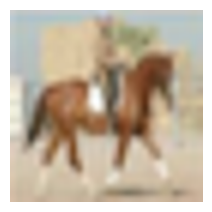

[train-27374] Ваш класс (0=airplane, 1=automobile, 2=bird, 3=cat, 4=deer, 5=dog, 6=frog, 7=horse, 8=ship, 9=truck); q - выход: 7
   VLM: класс=horse; подпись: A brown horse standing in front of a building.
   Оценка подписи: 0=неверна, 1=частично, 2=верна: 2


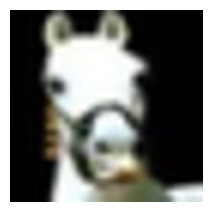

[train-11019] Ваш класс (0=airplane, 1=automobile, 2=bird, 3=cat, 4=deer, 5=dog, 6=frog, 7=horse, 8=ship, 9=truck); q - выход: 7
   VLM: класс=horse; подпись: A cartoon horse with a white face and black mane.
   Оценка подписи: 0=неверна, 1=частично, 2=верна: 2


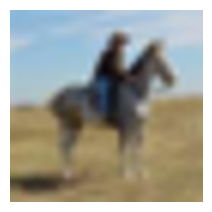

[train-29499] Ваш класс (0=airplane, 1=automobile, 2=bird, 3=cat, 4=deer, 5=dog, 6=frog, 7=horse, 8=ship, 9=truck); q - выход: 7
   VLM: класс=horse; подпись: A person riding a horse in a grassy field.
   Оценка подписи: 0=неверна, 1=частично, 2=верна: 2


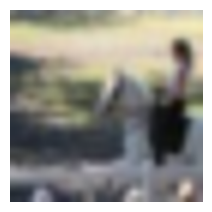

[train-40659] Ваш класс (0=airplane, 1=automobile, 2=bird, 3=cat, 4=deer, 5=dog, 6=frog, 7=horse, 8=ship, 9=truck); q - выход: 7
   VLM: класс=dog; подпись: A dog wearing a black jacket standing in a grassy field.
   Оценка подписи: 0=неверна, 1=частично, 2=верна: 0


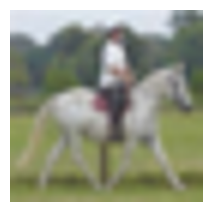

[train-14741] Ваш класс (0=airplane, 1=automobile, 2=bird, 3=cat, 4=deer, 5=dog, 6=frog, 7=horse, 8=ship, 9=truck); q - выход: 7
   VLM: класс=horse; подпись: A person riding a white horse in a grassy field.
   Оценка подписи: 0=неверна, 1=частично, 2=верна: 2


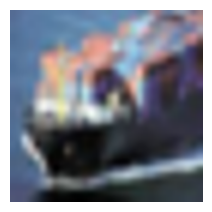

[train-05643] Ваш класс (0=airplane, 1=automobile, 2=bird, 3=cat, 4=deer, 5=dog, 6=frog, 7=horse, 8=ship, 9=truck); q - выход: 8
   VLM: класс=ship; подпись: A large ship sailing on the ocean.
   Оценка подписи: 0=неверна, 1=частично, 2=верна: 2


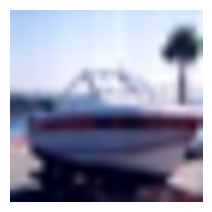

[train-06789] Ваш класс (0=airplane, 1=automobile, 2=bird, 3=cat, 4=deer, 5=dog, 6=frog, 7=horse, 8=ship, 9=truck); q - выход: 8
   VLM: класс=ship; подпись: A small boat floating on calm water near a palm tree.
   Оценка подписи: 0=неверна, 1=частично, 2=верна: 1


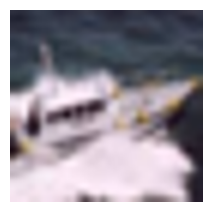

[train-31938] Ваш класс (0=airplane, 1=automobile, 2=bird, 3=cat, 4=deer, 5=dog, 6=frog, 7=horse, 8=ship, 9=truck); q - выход: 8
   VLM: класс=airplane; подпись: A white airplane flying over water.
   Оценка подписи: 0=неверна, 1=частично, 2=верна: 0


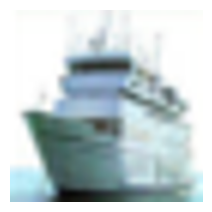

[train-06139] Ваш класс (0=airplane, 1=automobile, 2=bird, 3=cat, 4=deer, 5=dog, 6=frog, 7=horse, 8=ship, 9=truck); q - выход: 8
   VLM: класс=ship; подпись: A large ship with multiple decks.
   Оценка подписи: 0=неверна, 1=частично, 2=верна: 2


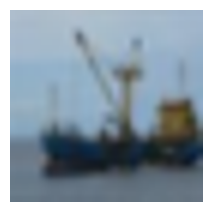

[train-29493] Ваш класс (0=airplane, 1=automobile, 2=bird, 3=cat, 4=deer, 5=dog, 6=frog, 7=horse, 8=ship, 9=truck); q - выход: 8
   VLM: класс=ship; подпись: A large ship with cranes on its deck.
   Оценка подписи: 0=неверна, 1=частично, 2=верна: 2


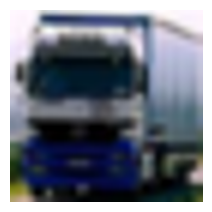

[train-00964] Ваш класс (0=airplane, 1=automobile, 2=bird, 3=cat, 4=deer, 5=dog, 6=frog, 7=horse, 8=ship, 9=truck); q - выход: 9
   VLM: класс=truck; подпись: A blue truck driving on a road.
   Оценка подписи: 0=неверна, 1=частично, 2=верна: 2


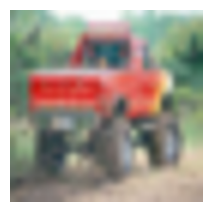

[train-38406] Ваш класс (0=airplane, 1=automobile, 2=bird, 3=cat, 4=deer, 5=dog, 6=frog, 7=horse, 8=ship, 9=truck); q - выход: 9
   VLM: класс=truck; подпись: A red truck driving on a dirt road surrounded by greenery.
   Оценка подписи: 0=неверна, 1=частично, 2=верна: 2


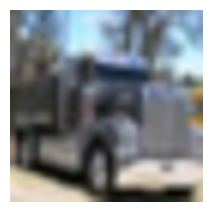

[train-48126] Ваш класс (0=airplane, 1=automobile, 2=bird, 3=cat, 4=deer, 5=dog, 6=frog, 7=horse, 8=ship, 9=truck); q - выход: 9
   VLM: класс=truck; подпись: A large black truck driving down a road.
   Оценка подписи: 0=неверна, 1=частично, 2=верна: 2


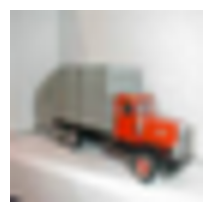

[train-44683] Ваш класс (0=airplane, 1=automobile, 2=bird, 3=cat, 4=deer, 5=dog, 6=frog, 7=horse, 8=ship, 9=truck); q - выход: 9
   VLM: класс=truck; подпись: A toy truck with red details and a white body.
   Оценка подписи: 0=неверна, 1=частично, 2=верна: 1


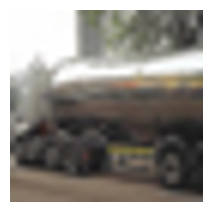

[train-26955] Ваш класс (0=airplane, 1=automobile, 2=bird, 3=cat, 4=deer, 5=dog, 6=frog, 7=horse, 8=ship, 9=truck); q - выход: 9
   VLM: класс=truck; подпись: A large truck parked in front of a building.
   Оценка подписи: 0=неверна, 1=частично, 2=верна: 2
{
 "n_audited": 50,
 "n_planned": 50,
 "complete": true,
 "reviewers": [
  "expert"
 ],
 "caption_score_mean": 1.42,
 "caption_score_dist": {
  "2": 32,
  "1": 7,
  "0": 11
 },
 "agreement_expert_vs_vlm": 0.88,
 "agreement_expert_vs_gold": 1.0,
 "agreement_vlm_vs_gold": 0.88,
 "kappa_expert_vs_vlm": 0.8666666666666667
}


In [20]:
import matplotlib.pyplot as plt
N_AUDIT_PER_CLASS = 2 if FAST_DEV_RUN else 5        # полный режим: 50 train-изображений (по 5 на класс)
AUDIT_PATH = ARTIFACTS / 'human_audit.jsonl'
rec_by_id = {r['id']: r for r in records}

def make_audit_sample():
    ann = {r['id']: r for r in load_jsonl(ANN_PATH)}
    r_ = np.random.RandomState(SEED + 1); sample = []
    for name in CLASSES:
        ids = [r['id'] for r in records if r['split'] == 'train' and r['gold_class'] == name and ann[r['id']]['valid']]
        sample += list(r_.choice(ids, min(N_AUDIT_PER_CLASS, len(ids)), replace=False))
    return [str(i) for i in sample]

def collect_audit(sample, reviewer):
    """Интерактивная экспертная проверка. Эксперт СНАЧАЛА называет класс сам (без подсказки VLM), затем оценивает подпись.
    Запись дописывается сразу; ввод 'q' прерывает сессию, повторный запуск продолжает с того же места."""
    ann = {r['id']: r for r in load_jsonl(ANN_PATH)}; done = {r['id'] for r in load_jsonl(AUDIT_PATH)}
    menu = ', '.join(f'{k}={c}' for k, c in enumerate(CLASSES))
    with AUDIT_PATH.open('a') as f:
        for i in sample:
            if i in done: continue
            plt.figure(figsize=(2.5, 2.5)); plt.imshow(Image.open(rec_by_id[i]['path'])); plt.axis('off'); plt.show()
            a = input(f'[{i}] Ваш класс ({menu}); q - выход: ').strip()
            if a.lower() == 'q': break
            if not a.isdigit() or int(a) >= len(CLASSES): print('пропущено: нужен номер класса'); continue
            parsed = ann[i]['parsed']
            print(f"   VLM: класс={parsed['class_name']}; подпись: {parsed['caption']}")
            s = input('   Оценка подписи: 0=неверна, 1=частично, 2=верна: ').strip()
            if s not in ('0', '1', '2'): print('пропущено: нужна оценка 0/1/2'); continue
            f.write(json.dumps({'id': i, 'reviewer': reviewer, 'expert_class': CLASSES[int(a)], 'vlm_class': parsed['class_name'],
                                'caption': parsed['caption'], 'caption_score': int(s),
                                'timestamp': time.strftime('%Y-%m-%dT%H:%M:%S')}, ensure_ascii=False) + '\n'); f.flush()

AUDIT_OK, audit_summary = False, None
if HAVE_VLM:
    sample = make_audit_sample(); save_json('audit_sample.json', {'seed': SEED + 1, 'ids': sample})
    if len({r['id'] for r in load_jsonl(AUDIT_PATH)} & set(sample)) < len(sample):
        collect_audit(sample, reviewer=input('Имя/идентификатор эксперта: ').strip() or 'reviewer')
    aud = [r for r in load_jsonl(AUDIT_PATH) if r['id'] in set(sample)]
    AUDIT_OK = len(aud) == len(sample)
    if aud:
        ex = [r['expert_class'] for r in aud]; vl = [r['vlm_class'] for r in aud]; gd = [gold_cls[r['id']] for r in aud]
        audit_summary = {'n_audited': len(aud), 'n_planned': len(sample), 'complete': AUDIT_OK,
                         'reviewers': sorted({r['reviewer'] for r in aud}),
                         'caption_score_mean': float(np.mean([r['caption_score'] for r in aud])),
                         'caption_score_dist': dict(Counter(r['caption_score'] for r in aud)),
                         'agreement_expert_vs_vlm': float(np.mean([a == b for a, b in zip(ex, vl)])),
                         'agreement_expert_vs_gold': float(np.mean([a == b for a, b in zip(ex, gd)])),
                         'agreement_vlm_vs_gold': float(np.mean([a == b for a, b in zip(vl, gd)])),
                         'kappa_expert_vs_vlm': float(cohen_kappa_score(ex, vl))}
        save_json('audit_summary.json', audit_summary); print(json.dumps(audit_summary, ensure_ascii=False, indent=1))
    if not AUDIT_OK: print(f'ВНИМАНИЕ: аудит не завершён ({len(aud)}/{len(sample)}); запустите ячейку ещё раз. Подтверждённого аудита нет.')
else:
    print('FAST_DEV_RUN: экспертная оценка не выполняется и не имитируется.')

### Визуальные признаки для downstream

*Вес: 1 балл.*

**Постановка.** Этап «визуальные признаки для downstream» необходим для воспроизводимого предметного сравнения. Результат этого шага нельзя заменить синтетической оценкой или произвольной метрикой.

Выполните следующие действия:

1. Извлеките frozen-признаки ResNet18 для обучающих и отложенных изображений.
2. Сохраните и предъявите признаки ResNet18 train/test.

**Результат.** признаки ResNet18 train/test.

**Критерий принятия.** Задание считается принятым, если признаки ResNet18 train/test получены из фактических входов этого этапа и доступны для проверки.

In [21]:
import torch
from torchvision import models, transforms
device = 'cuda' if torch.cuda.is_available() else 'cpu'
resnet = models.resnet18(weights=models.ResNet18_Weights.IMAGENET1K_V1)
resnet.fc = torch.nn.Identity()                       # 512-мерный вектор после global average pooling
resnet.eval().to(device)
for p_ in resnet.parameters(): p_.requires_grad_(False)            # frozen
tfm = transforms.Compose([transforms.Resize(224), transforms.ToTensor(),
                          transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])])

@torch.no_grad()
def extract(paths, bs=64):
    feats = []
    for k in range(0, len(paths), bs):
        x = torch.stack([tfm(Image.open(p).convert('RGB')) for p in paths[k:k + bs]]).to(device)
        feats.append(resnet(x).float().cpu().numpy())
    return np.concatenate(feats)

tr = [r for r in records if r['split'] == 'train']; te = [r for r in records if r['split'] == 'test']
X_train, X_test = extract([r['path'] for r in tr]), extract([r['path'] for r in te])
y_train = np.array([r['gold_label'] for r in tr]); y_test = np.array([r['gold_label'] for r in te])
train_ids, test_ids = [r['id'] for r in tr], [r['id'] for r in te]
print('X_train', X_train.shape, 'X_test', X_test.shape, 'device', device)
np.savez_compressed(ARTIFACTS / 'resnet18_features.npz', X_train=X_train, X_test=X_test, y_train=y_train, y_test=y_test,
                    train_ids=np.array(train_ids), test_ids=np.array(test_ids))

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 159MB/s]


X_train (1000, 512) X_test (500, 512) device cuda


### Классификаторы при равном бюджете

*Вес: 1 балл.*

**Постановка.** Этап «классификаторы при равном бюджете» необходим для воспроизводимого предметного сравнения. Результат этого шага нельзя заменить синтетической оценкой или произвольной метрикой.

Выполните следующие действия:

1. Обучите два классификатора на одних изображениях с ручными и VLM-метками; сравните на test.
2. Сохраните и предъявите artifacts/downstream.json и подтверждённый аудит.

**Результат.** artifacts/downstream.json и подтверждённый аудит.

**Критерий принятия.** Задание считается принятым, если artifacts/downstream.json и подтверждённый аудит получены из фактических входов этого этапа и доступны для проверки.

In [22]:
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import accuracy_score, f1_score

if not HAVE_VLM:
    print('FAST_DEV_RUN: downstream не вычисляется (нет реальных VLM-меток).')
else:
    assert AUDIT_OK and audit_summary, 'Нужен завершённый экспертный аудит (ячейка экспертной оценки): без него downstream не принимается.'
    ann = {r['id']: r for r in load_jsonl(ANN_PATH)}
    keep = np.array([ann[i]['valid'] for i in train_ids])                    # одни и те же изображения для обоих классификаторов
    Xk = X_train[keep]; y_manual = y_train[keep]
    y_vlm = np.array([CLASSES.index(ann[i]['parsed']['class_name']) for i, k in zip(train_ids, keep) if k])
    mk = lambda: make_pipeline(StandardScaler(), LogisticRegression(max_iter=3000))
    clf_manual, clf_vlm = mk().fit(Xk, y_manual), mk().fit(Xk, y_vlm)        # равный бюджет: те же n изображений, разные метки
    res = {}
    for name, clf in (('manual_labels', clf_manual), ('vlm_labels', clf_vlm)):
        pr = clf.predict(X_test)
        res[name] = {'accuracy': float(accuracy_score(y_test, pr)), 'macro_f1': float(f1_score(y_test, pr, average='macro')),
                     'per_class_recall': {c: float(np.mean(pr[y_test == k] == k)) for k, c in enumerate(CLASSES)}}
    pm, pv = clf_manual.predict(X_test) == y_test, clf_vlm.predict(X_test) == y_test
    bs = np.random.RandomState(SEED); diffs = []
    for _ in range(2000):                                                     # парный bootstrap по test
        ix = bs.randint(0, len(y_test), len(y_test)); diffs.append(pm[ix].mean() - pv[ix].mean())
    out = {'n_train_images_used': int(keep.sum()), 'n_train_images_total': int(len(keep)),
           'vlm_label_coverage_train': float(keep.mean()), 'vlm_label_accuracy_on_train_vs_gold': float(np.mean(y_vlm == y_manual)),
           'n_test': int(len(y_test)), 'classifier': 'StandardScaler + LogisticRegression на frozen ResNet18-признаках',
           'results': res, 'accuracy_gap_manual_minus_vlm': float(pm.mean() - pv.mean()),
           'gap_bootstrap_95ci': [float(np.percentile(diffs, 2.5)), float(np.percentile(diffs, 97.5))],
           'audit_confirmed': True, 'audit': audit_summary}
    save_json('downstream.json', out)
    print(json.dumps({k: v for k, v in out.items() if k != 'audit'}, ensure_ascii=False, indent=1)[:2500])

{
 "n_train_images_used": 994,
 "n_train_images_total": 1000,
 "vlm_label_coverage_train": 0.994,
 "vlm_label_accuracy_on_train_vs_gold": 0.8360160965794768,
 "n_test": 500,
 "classifier": "StandardScaler + LogisticRegression на frozen ResNet18-признаках",
 "results": {
  "manual_labels": {
   "accuracy": 0.794,
   "macro_f1": 0.7939974622867128,
   "per_class_recall": {
    "airplane": 0.86,
    "automobile": 0.88,
    "bird": 0.66,
    "cat": 0.72,
    "deer": 0.72,
    "dog": 0.78,
    "frog": 0.86,
    "horse": 0.82,
    "ship": 0.84,
    "truck": 0.8
   }
  },
  "vlm_labels": {
   "accuracy": 0.658,
   "macro_f1": 0.6639337587494569,
   "per_class_recall": {
    "airplane": 0.74,
    "automobile": 0.84,
    "bird": 0.66,
    "cat": 0.36,
    "deer": 0.54,
    "dog": 0.84,
    "frog": 0.58,
    "horse": 0.68,
    "ship": 0.54,
    "truck": 0.8
   }
  }
 },
 "accuracy_gap_manual_minus_vlm": 0.136,
 "gap_bootstrap_95ci": [
  0.09794999999999998,
  0.17400000000000004
 ],
 "audit_conf

### Творческое мини-исследование

*Бонус: до 1 балла сверх 10.*

**Постановка.** Сформулируйте проверяемую гипотезу о предметном ограничении метода данной лабораторной и проверьте её на дополнительных реальных входах без использования отложенного теста для выбора гипотезы. Сопоставьте результаты с основным экспериментом и объясните расхождения.

**Результат.** Отдельный файл artifacts/bonus.md с гипотезой, протоколом, наблюдениями и выводом.

**Критерий принятия.** Задание считается принятым, если гипотеза проверена по сохранённым предсказаниям или изображениям и приведено воспроизводимое сравнение.

## Анализ результатов

Сопоставьте измеренные показатели на фиксированной отложенной выборке, укажите ограничения выборки и разберите ошибки по сохранённым предсказаниям. FAST_DEV_RUN не является основанием для итогового вывода.

## Требования к сдаче

Запустите полный режим, приложите конфигурацию, версии зависимостей, артефакты и инструкции повторного запуска. Не сдавайте фиктивные измерения.

## Инструкция повторного запуска

1. Colab: среда GPU (T4); `%pip install -q "transformers>=4.51,<5" accelerate bitsandbytes pillow pydantic scikit-learn torchvision matplotlib`.
2. Смонтируйте Drive и скопируйте `artifacts/` на него **до** начала инференса (разметка возобновляема: `annotations.jsonl` дописывается построчно).
3. `FAST_DEV_RUN=True` — проверка загрузки данных, схемы и парсера без VLM; `FAST_DEV_RUN=False` — полный эксперимент (≈1500 вызовов VLM + ручной аудит).
4. Запустить Run all; ячейка экспертной оценки интерактивна (`input`), её нельзя заменить автоматическим заполнением.

In [24]:
import importlib.metadata as md
def ver(n):
    try: return md.version(n)
    except Exception: return None
save_json('environment.json', {'versions': {n: ver(n) for n in ['torch', 'torchvision', 'transformers', 'accelerate', 'bitsandbytes',
                                                               'pydantic', 'scikit-learn', 'numpy', 'pillow']},
                               'config': {'SEED': SEED, 'FAST_DEV_RUN': FAST_DEV_RUN, 'MODEL': MODEL_NAME, 'MAX_RETRIES': MAX_RETRIES,
                                          'N_TRAIN_PER_CLASS': N_TRAIN_PER_CLASS, 'N_TEST_PER_CLASS': N_TEST_PER_CLASS,
                                          'N_AUDIT_PER_CLASS': N_AUDIT_PER_CLASS, 'prompt_sha1': PROMPT_SHA1}})
print(sorted(p.name for p in ARTIFACTS.iterdir()))

['annotation_schema.json', 'annotations.jsonl', 'audit_sample.json', 'audit_summary.json', 'bonus_annotations.jsonl', 'confusion_matrix.png', 'downstream.json', 'environment.json', 'human_audit.jsonl', 'images.jsonl', 'prompt.txt', 'quality.json', 'resnet18_features.npz', 'schema_check.json', 'selection.json']
